In [2]:
import json
from datetime import date
from pathlib import Path

import dayplot as dp
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import yaml

from common import daterange, determine_descriptives

with open("../config.budapest.yaml", "r") as fp:
    config = yaml.safe_load(fp)

with open("plotting_config.yaml", "r") as fp:
    plotting_config = yaml.safe_load(fp)

Path(f"../output/{config['city']}/descriptives").mkdir(parents=True, exist_ok=True)

In [4]:
try:
    with open(f"../output/{config['city']}/descriptive/counts_2023.json", "r") as fp:
        counts_2023 = json.load(fp)
except FileNotFoundError:
    # runs 3 minutes for 2023-10-01--2023-12-31
    counts_2023 = {}
    for i in daterange(date(2023, 10, 1), date(2023, 12, 31)):
        counts_2023[i.strftime("%Y-%m-%d")] = determine_descriptives(
            i, config["dirs"]["raw_source"]
        )
    with open(f"../output/{config['city']}/descriptive/counts_2023.json", "w") as fp:
        json.dump(counts_2023, fp, indent=1)


In [5]:
try:
    with open(f"../output/{config['city']}/descriptive/counts_2024.json", "r") as fp:
        counts_2024 = json.load(fp)
except FileNotFoundError:
    # runs 5 minutes
    counts_2024 = {}
    for i in daterange(date(2024, 1, 1), date(2024, 2, 29)):
        counts_2024[i.strftime("%Y-%m-%d")] = determine_descriptives(
            i, config["dirs"]["raw_source"]
        )
    for i in daterange(date(2024, 10, 1), date(2024, 12, 31)):
        counts_2024[i.strftime("%Y-%m-%d")] = determine_descriptives(i)
    with open(f"../output/{config['city']}/descriptive/counts_2024.json", "w") as fp:
        json.dump(counts_2024, fp, indent=1)


In [ ]:
c25 = {}
for i in daterange(date(2025, 10, 1), date(2025, 10, 31)):
    c25[i.strftime("%Y-%m-%d")] = determine_descriptives(
        i, config["dirs"]["raw_source"]
    )

In [7]:
try:
    with open(f"../output/{config['city']}/descriptive/counts_2025.json", "r") as fp:
        counts_2025 = json.load(fp)
except FileNotFoundError:
    # runs 17 minutes
    counts_2025 = {}
    for i in daterange(date(2025, 1, 1), date(2025, 12, 31)):
        counts_2025[i.strftime("%Y-%m-%d")] = determine_descriptives(
            i, config["dirs"]["raw_source"]
        )
    with open(f"../output/{config['city']}/descriptive/counts_2025.json", "w") as fp:
        json.dump(counts_2025, fp, indent=1)

In [8]:
def counts_to_dataframe(counts: dict[str, dict[str, int]]) -> pl.DataFrame:
    records = []
    for k, v in counts.items():
        records.append(
            [
                date(*map(int, k.split("-"))),
                v["number_of_records"],
                v["number_of_unique_devices"],
            ]
        )
    return pl.from_records(
        records,
        schema=["day", "number_of_records", "number_of_unique_devices"],
        orient="row",
    )

In [9]:
cdf_23 = counts_to_dataframe(counts_2023)
cdf_24 = counts_to_dataframe(counts_2024)
cdf_25 = counts_to_dataframe(counts_2025)

In [10]:
rn_min = np.min(
    [
        cdf_23["number_of_records"].min(),
        cdf_24["number_of_records"].min(),
        cdf_25["number_of_records"].min(),
    ]
)
rn_max = np.max(
    [
        cdf_23["number_of_records"].max(),
        cdf_24["number_of_records"].max(),
        cdf_25["number_of_records"].max(),
    ]
)

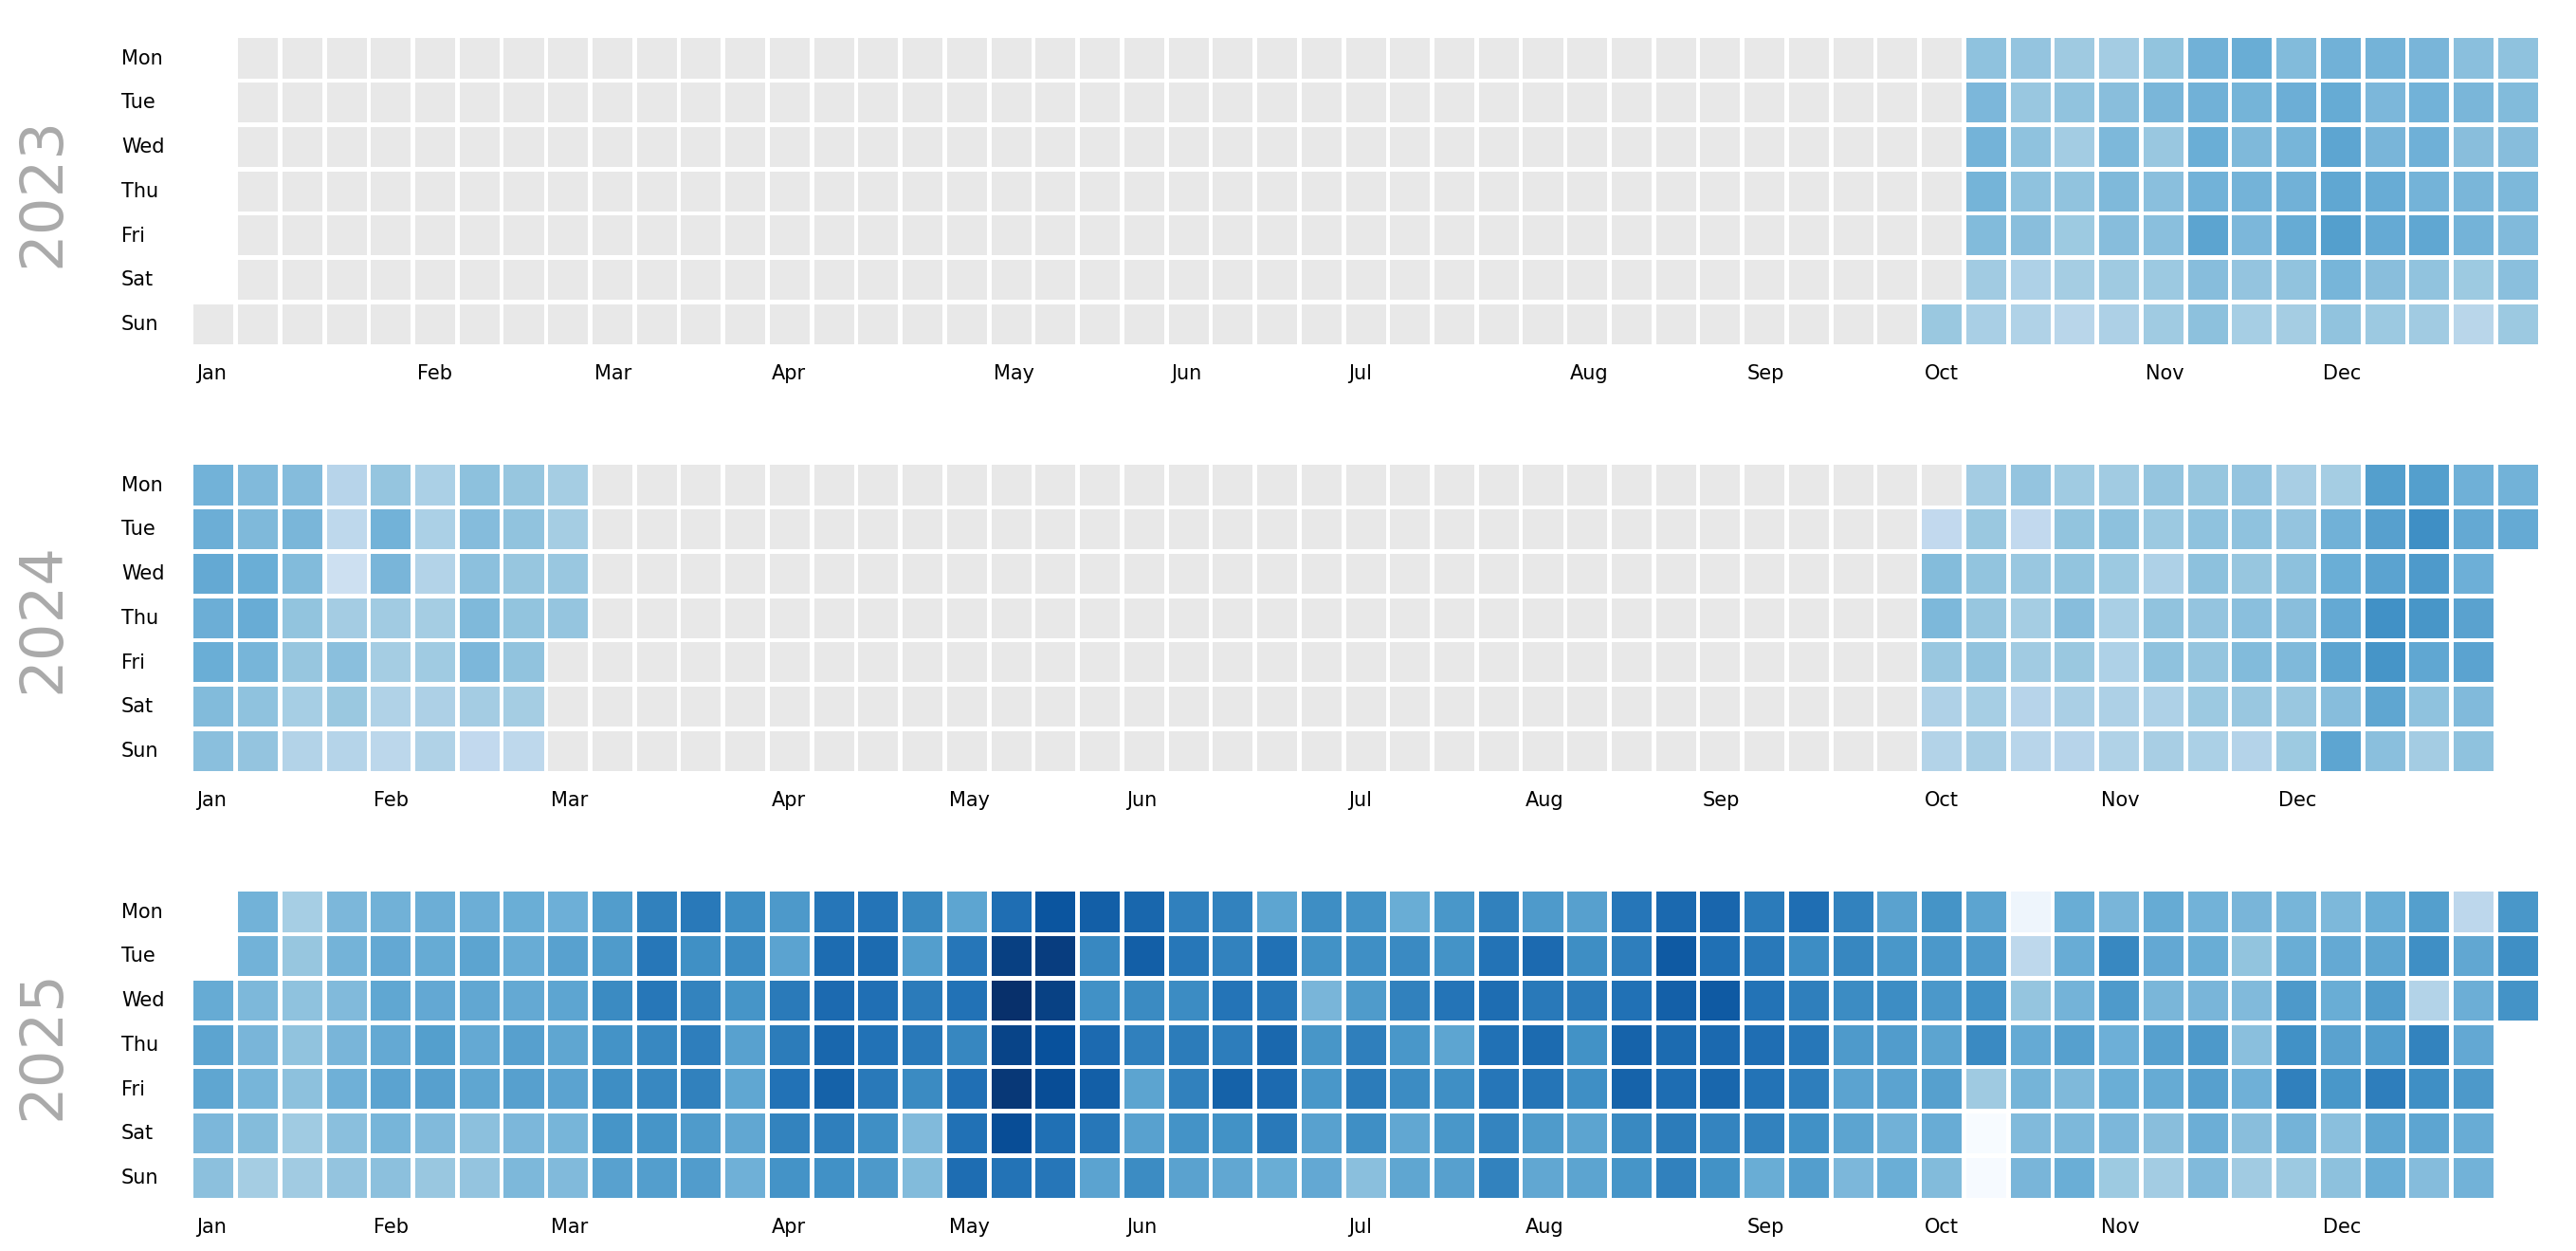

In [ ]:
fig, axs = plt.subplots(nrows=3, figsize=(18, 9), dpi=150, layout="constrained")
_ = dp.calendar(
    dates=cdf_23["day"],
    values=cdf_23["number_of_records"],
    start_date="2023-01-01",
    end_date="2023-12-31",
    week_starts_on="Monday",
    ax=axs[0],
    cmap="Blues",
    vmin=rn_min,
    vmax=rn_max,
)
_ = dp.calendar(
    dates=cdf_24["day"],
    values=cdf_24["number_of_records"],
    start_date="2024-01-01",
    end_date="2024-12-31",
    week_starts_on="Monday",
    ax=axs[1],
    cmap="Blues",
    vmin=rn_min,
    vmax=rn_max,
)
_ = dp.calendar(
    dates=cdf_25["day"],
    values=cdf_25["number_of_records"],
    start_date="2025-01-01",
    end_date="2025-12-31",
    week_starts_on="Monday",
    ax=axs[2],
    cmap="Blues",
    vmin=rn_min,
    vmax=rn_max,
)
text_args = {
    "x": -4,
    "y": 3.5,
    "size": 30,
    "rotation": 90,
    "color": "#aaa",
    "va": "center",
    # font=fontlight
}
axs[0].text(s="2023", **text_args)
axs[1].text(s="2024", **text_args)
axs[2].text(s="2025", **text_args)


for i in ["png", "svg"]:
    fig.savefig(
        # f"../output/{config['city']}/descriptive/number_of_records_dayplot.{i}",
        f"../docs/figures/number_of_records_dayplot.{i}",
        metadata=plotting_config["metadata"][i],
    )

In [17]:
ud_min = np.min(
    [
        cdf_23["number_of_unique_devices"].min(),
        cdf_24["number_of_unique_devices"].min(),
        cdf_25["number_of_unique_devices"].min(),
    ]
)
ud_max = np.max(
    [
        cdf_23["number_of_unique_devices"].max(),
        cdf_24["number_of_unique_devices"].max(),
        cdf_25["number_of_unique_devices"].max(),
    ]
)
up_mean = np.median(
    [
        cdf_23["number_of_unique_devices"].max(),
        cdf_24["number_of_unique_devices"].max(),
        cdf_25["number_of_unique_devices"].max(),
    ]
)

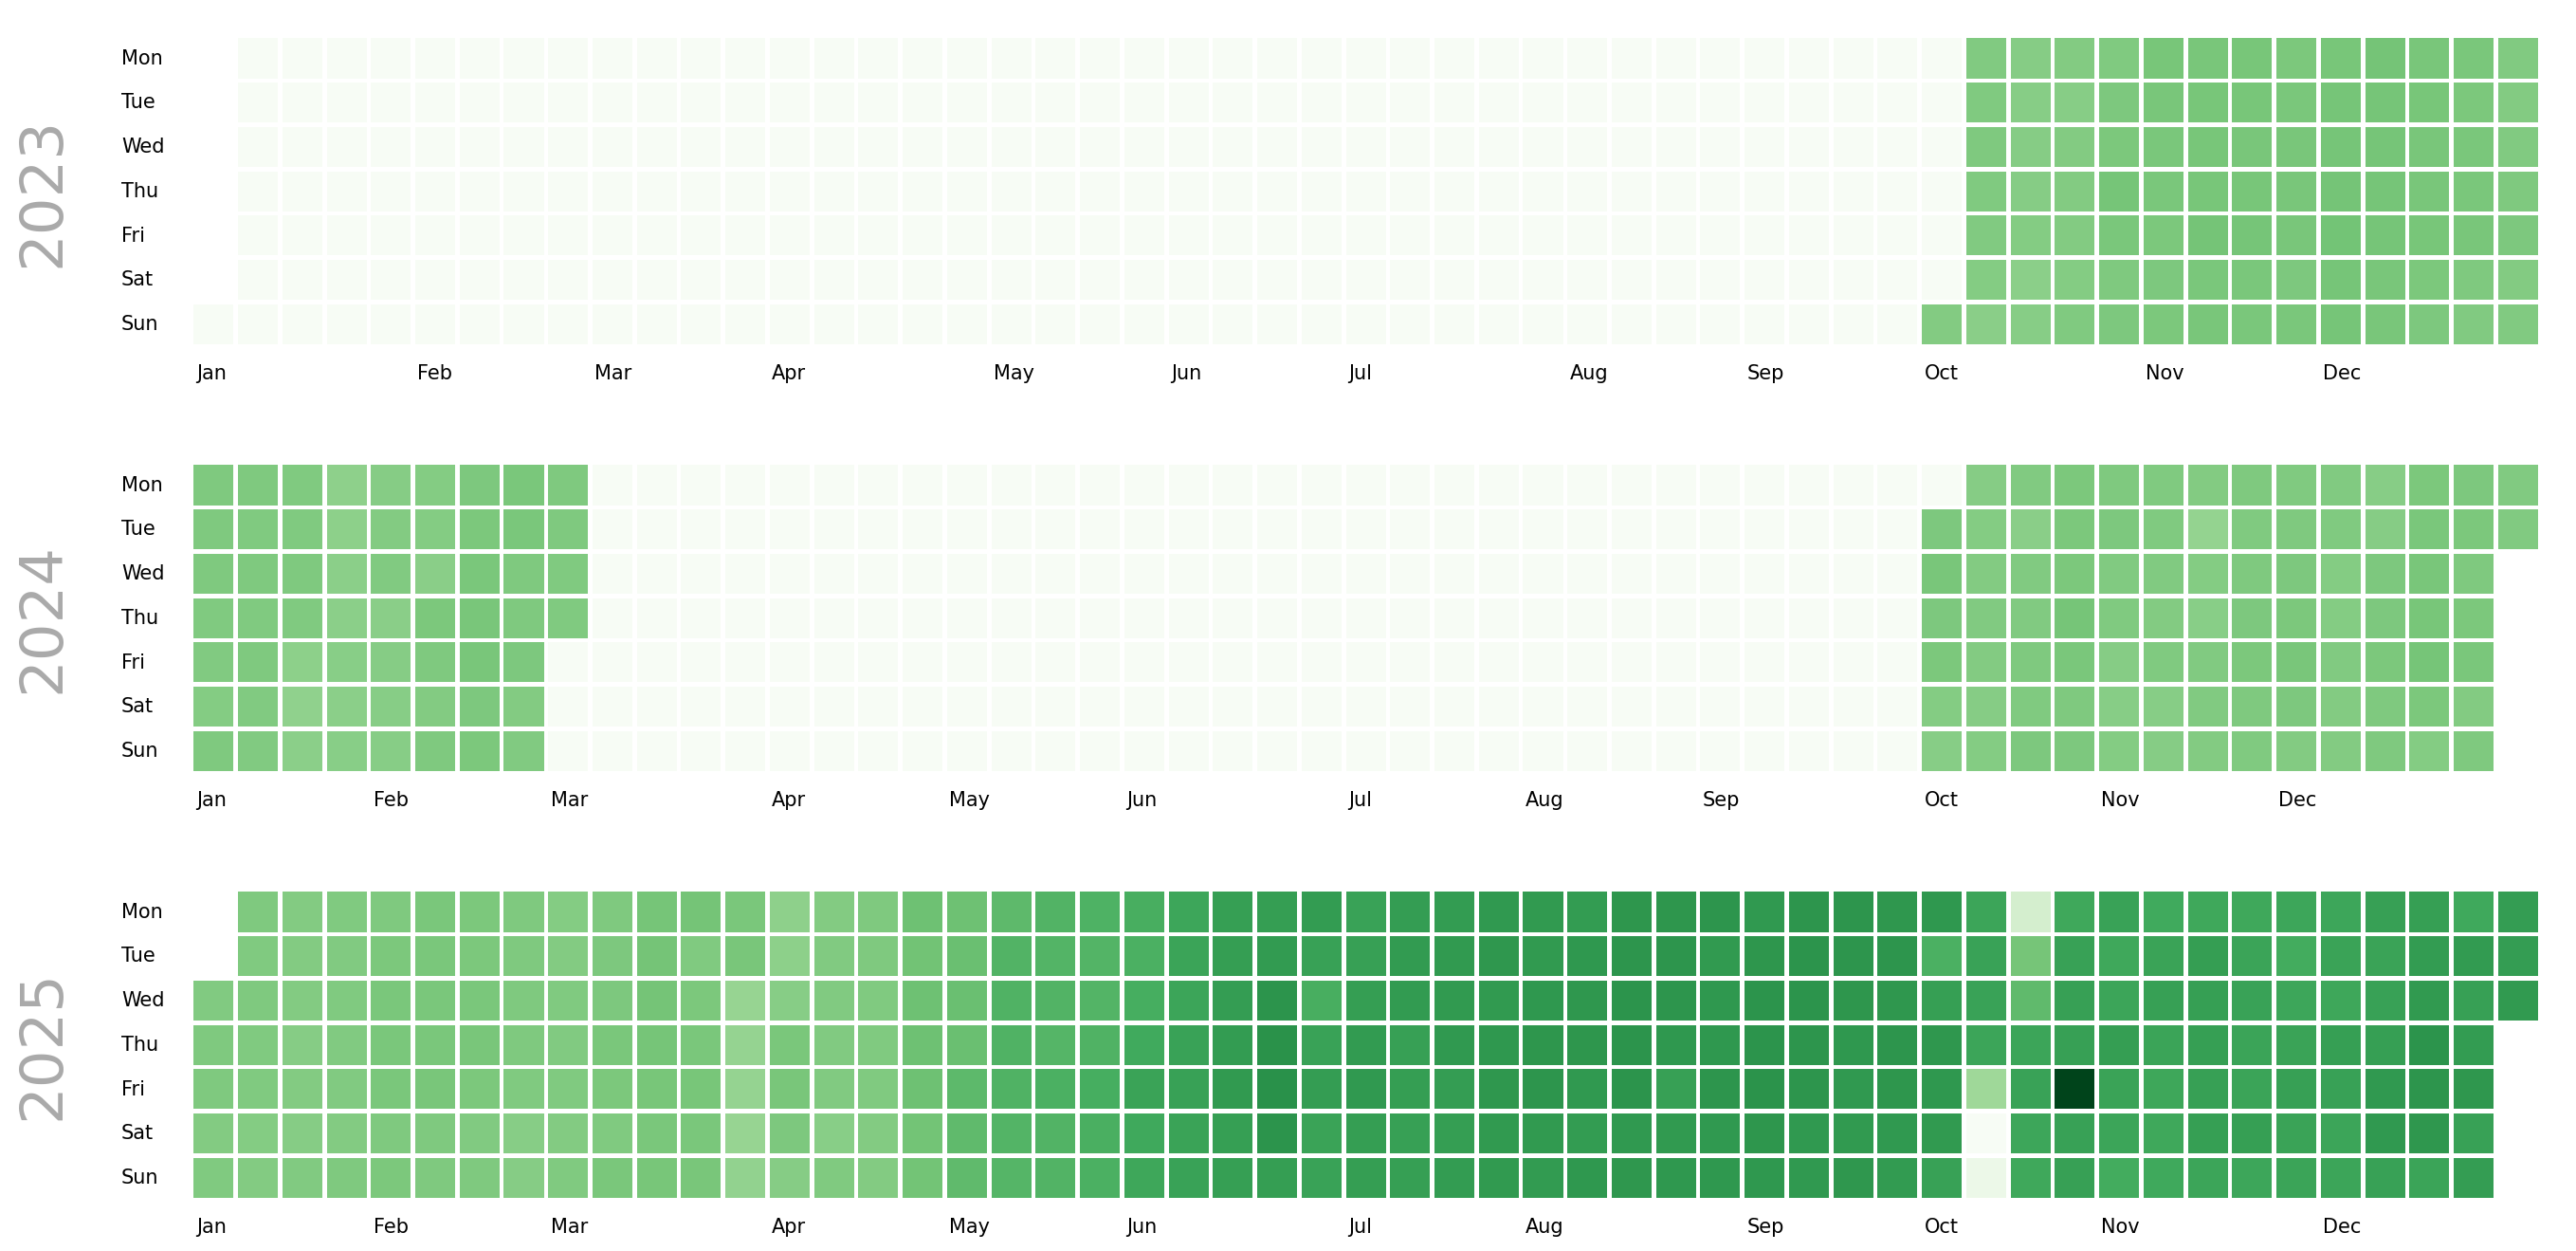

In [ ]:
fig, axs = plt.subplots(nrows=3, figsize=(18, 9), dpi=150, layout="constrained")
_ = dp.calendar(
    dates=cdf_23["day"],
    values=cdf_23["number_of_unique_devices"],
    start_date="2023-01-01",
    end_date="2023-12-31",
    week_starts_on="Monday",
    ax=axs[0],
    cmap="Greens",
    vmin=ud_min,
    vmax=ud_max,
    vcenter=up_mean,
)
_ = dp.calendar(
    dates=cdf_24["day"],
    values=cdf_24["number_of_unique_devices"],
    start_date="2024-01-01",
    end_date="2024-12-31",
    week_starts_on="Monday",
    ax=axs[1],
    cmap="Greens",
    vmin=ud_min,
    vmax=ud_max,
    vcenter=up_mean,
)
_ = dp.calendar(
    dates=cdf_25["day"],
    values=cdf_25["number_of_unique_devices"],
    start_date="2025-01-01",
    end_date="2025-12-31",
    week_starts_on="Monday",
    ax=axs[2],
    cmap="Greens",
    vmin=ud_min,
    vmax=ud_max,
    vcenter=up_mean,
)
text_args = {
    "x": -4,
    "y": 3.5,
    "size": 30,
    "rotation": 90,
    "color": "#aaa",
    "va": "center",
    # font=fontlight
}
axs[0].text(s="2023", **text_args)
axs[1].text(s="2024", **text_args)
axs[2].text(s="2025", **text_args)


for i in ["png", "svg"]:
    fig.savefig(
        # f"../output/{config['city']}/descriptive/number_of_unique_devices_dayplot.{i}",
        f"../docs/figures/number_of_unique_devices_dayplot.{i}",
        metadata=plotting_config["metadata"][i],
    )